In [1]:
from pathlib import Path

import numpy as np
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from plot_style import apply

FIG = Path("figs")
DATA_PATH = FIG / "data" / "global_flow_schematic_data.npz"
OUTPUT = FIG / "Fig1.pdf"

apply()

MOTIF_NAMES = ("VI", "VII", "VIII")
MOTIF_TITLES = ("One filled\ntriangle", "Two filled\ntriangles", "Three filled\ntriangles")
RATIOS = (1.20, 1.45, 1.63)
TWO_PI = 2.0 * np.pi
LAUNCH = np.deg2rad([78.0, 258.0])

with np.load(DATA_PATH) as archive:
    data = {key: archive[key] for key in archive.files}

In [2]:
MOTIFS = {
    "VI":   dict(triangles=[(1, 2, 4)],
                 edges=[(1, 2), (1, 4), (2, 4), (1, 3)]),
    "VII":  dict(triangles=[(1, 2, 4), (1, 3, 4)],
                 edges=[(1, 2), (1, 3), (1, 4), (2, 4), (3, 4)]),
    "VIII": dict(triangles=[(1, 2, 3), (1, 2, 4), (1, 3, 4)],
                 edges=[(1, 2), (1, 3), (1, 4), (2, 3), (2, 4), (3, 4)]),
}

NODE_FACE  = "#D6EAF8"
NODE_EDGE  = "#7BAFD4"
NODE_SIZE  = 8
NODE_LW    = 0.75
EDGE_COLOR = "#7D8CC4"

TETRA_POS = {
    1: (0.50, 0.90),
    2: (0.12, 0.16),
    3: (0.88, 0.16),
    4: (0.55, 0.47),
}

TETRA_LABEL_OFFSET = {
    1: (0.00, 0.115),
    2: (-0.085, -0.085),
    3: (+0.085, -0.085),
    4: (0.00, -0.135),
}

TETRA_EDGES = [(1, 2), (1, 3), (1, 4), (2, 3), (2, 4), (3, 4)]

COUNT_FILL = {1: "#FCEAEA", 2: "#F6D9D9", 3: "#F0CACA"}
DASH_BY_COUNT = {1: "#C2D2E0", 2: "#B4C6D7", 3: "#9FB4CA"}


def draw_tetra_motif(ax, name, node_label_size=9.6):
    faces = MOTIFS[name]["triangles"]
    active_edges = {tuple(sorted(edge)) for edge in MOTIFS[name]["edges"]}
    fill = COUNT_FILL[len(faces)]
    dash_color = DASH_BY_COUNT[len(faces)]

    for face in faces:
        xy = np.array([TETRA_POS[i] for i in face])
        ax.add_patch(mpatches.Polygon(
            xy, closed=True,
            facecolor=fill, alpha=1.0,
            edgecolor="none", zorder=1))

    for i, j in TETRA_EDGES:
        (x1, y1), (x2, y2) = TETRA_POS[i], TETRA_POS[j]
        if tuple(sorted((i, j))) in active_edges:
            ax.plot([x1, x2], [y1, y2], "-",
                    color=EDGE_COLOR, lw=0.85, zorder=3)
        else:
            ax.plot([x1, x2], [y1, y2],
                    linestyle=(0, (3.0, 2.0)),
                    color=dash_color, lw=0.66,
                    alpha=0.96, zorder=2)

    node_labels = {1: r"$a$", 2: r"$b$", 3: r"$c$", 4: r"$d$"}
    for k, (x, y) in TETRA_POS.items():
        ax.plot(x, y, "o", ms=NODE_SIZE,
                markerfacecolor=NODE_FACE,
                markeredgecolor=NODE_EDGE,
                markeredgewidth=NODE_LW, zorder=5)
        dx, dy = TETRA_LABEL_OFFSET[k]
        ax.text(x + dx, y + dy, node_labels[k],
                ha="center", va="center",
                fontsize=node_label_size,
                color="#1a1a1a", zorder=6)

    ax.set_xlim(0.00, 1.00)
    ax.set_ylim(0.02, 1.02)
    ax.set_facecolor("none")
    ax.patch.set_alpha(0.0)
    ax.grid(False)
    ax.set_aspect("equal")
    ax.axis("off")


def wrap(x):
    return (np.asarray(x) + np.pi) % TWO_PI - np.pi


COL = {
    "inphase": "#4E7FB0",
    "inphase_fill": "#D8E6F3",
    "cl1": "#D2696A",
    "cl1_fill": "#F6DCDA",
    "cl2": "#DE9A5E",
    "cl2_fill": "#FAE7D1",
    "unres": "#9A9A9A",
    "unres_fill": "#E6E6E6",
    "ink": "#232323",
}

FILL = ListedColormap(
    [COL["unres_fill"], COL["inphase_fill"], COL["cl1_fill"], COL["cl2_fill"]]
)
NORM = BoundaryNorm([-1.5, -0.5, 0.5, 1.5, 2.5], 4)
MARK = [COL["unres"], COL["inphase"], COL["cl1"], COL["cl2"]]


def split_wrapped(x, y, jump=np.pi):
    cut = np.flatnonzero((np.abs(np.diff(x)) > jump) | (np.abs(np.diff(y)) > jump))
    return np.split(np.column_stack((x, y)), cut + 1)


def draw_flow_panel(ax, r, first=False):
    key = f"{r:.2f}"
    ax.imshow(
        data[f"basin_{key}"], origin="lower",
        extent=[-np.pi, np.pi, 0.0, TWO_PI],
        cmap=FILL, norm=NORM, interpolation="nearest", zorder=0,
    )

    wheel = data[f"wheel_{key}"]
    angles = data["angles"]
    for k, orbit in enumerate(data[f"orbits_{key}"]):
        destination = int(wheel[int(np.argmin(np.abs(angles - LAUNCH[k])))])
        colour = MARK[destination + 1]
        for segment in split_wrapped(wrap(orbit[:, 0]), orbit[:, 1] % TWO_PI):
            if len(segment) > 1:
                ax.plot(segment[:, 0], segment[:, 1], color=colour, lw=1.0, zorder=5)

    sinks = np.atleast_2d(data[f"sinks_{key}"])
    for i, q in enumerate(sinks):
        for y in ([q[1]] if i else [0.0, TWO_PI]):
            ax.plot(
                [q[0]], [y], marker="D" if i else "o", ms=3,
                color=MARK[i + 1], mew=0.8, zorder=7,
            )
    ax.plot([0.0], [np.pi], marker="x", ms=4, color=COL["ink"],
            mew=0.9, zorder=8)

    ax.set_xlim(-np.pi, np.pi)
    ax.set_ylim(0.0, TWO_PI)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xticks([-np.pi, 0.0, np.pi])
    ax.set_yticks([0.0, np.pi, TWO_PI])
    if first:
        ax.set_xticklabels([r"$-\pi$", "0", r"$\pi$"], fontsize=7.8)
    else:
        ax.set_xticklabels(["", "0", r"$\pi$"], fontsize=7.8)
    ax.set_xlabel(r"$\phi_{1}=\phi_{3}$", fontsize=8.6, labelpad=1.5)
    if first:
        ax.set_yticklabels(["0", r"$\pi$", r"$2\pi$"], fontsize=7.8)
        ax.set_ylabel(r"$\phi_{2}$", fontsize=8.6, labelpad=0.5)
    else:
        ax.set_yticklabels([])
    ax.tick_params(direction="in", length=2.4, width=0.7, pad=4.4)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.7)
        spine.set_color("0.45")

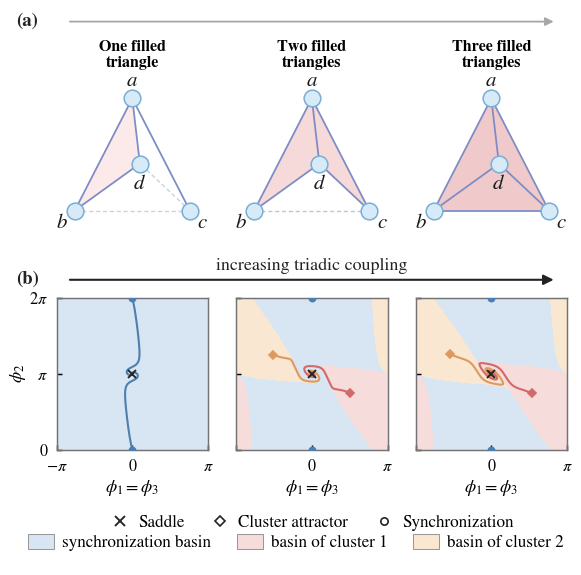

In [3]:
N_PANELS = 3
FIGURE_WIDTH_IN = 3.8
PANEL_GAP_IN = 0.10
LEFT_MARGIN_IN, RIGHT_MARGIN_IN = 0.28, 0.03
PANEL_WIDTH_IN = (
    FIGURE_WIDTH_IN - LEFT_MARGIN_IN - RIGHT_MARGIN_IN
    - (N_PANELS - 1) * PANEL_GAP_IN
) / N_PANELS

TOP_ARROW_H = 0.15
MOTIF_TITLE_H = 0.27
MOTIF_PANEL_H = PANEL_WIDTH_IN
ROW_GAP_H = 0.10
FLOW_ARROW_H = 0.22
FLOW_PANEL_H = PANEL_WIDTH_IN
LEGEND_H = 0.80
FIGURE_HEIGHT_IN = (TOP_ARROW_H + MOTIF_TITLE_H + MOTIF_PANEL_H + ROW_GAP_H
                    + FLOW_ARROW_H + FLOW_PANEL_H + LEGEND_H)

figure = plt.figure(figsize=(FIGURE_WIDTH_IN, FIGURE_HEIGHT_IN), facecolor="white")
grid = GridSpec(
    7, N_PANELS, figure=figure,
    height_ratios=[TOP_ARROW_H, MOTIF_TITLE_H, MOTIF_PANEL_H, ROW_GAP_H,
                   FLOW_ARROW_H, FLOW_PANEL_H, LEGEND_H],
    width_ratios=[1.0] * N_PANELS,
    hspace=0.1, wspace=PANEL_GAP_IN / PANEL_WIDTH_IN,
    left=LEFT_MARGIN_IN / FIGURE_WIDTH_IN,
    right=1.0 - RIGHT_MARGIN_IN / FIGURE_WIDTH_IN,
    top=1.0, bottom=0.0,
)

ax = figure.add_subplot(grid[0, :])
ax.annotate("", xy=(0.97, 0.32), xytext=(0.03, 0.32), xycoords="axes fraction",
            arrowprops=dict(arrowstyle="-|>", color="#a8a8a8", lw=0.9,
                            mutation_scale=8))
ax.text(-0.065, 0.32, "(a)", transform=ax.transAxes, clip_on=False,
        ha="left", va="center", fontsize=9.0, fontweight="bold",
        color=COL["ink"])
ax.axis("off")

for k, (name, title) in enumerate(zip(MOTIF_NAMES, MOTIF_TITLES)):
    title_ax = figure.add_subplot(grid[1, k])
    title_ax.text(0.5, 0.48, title, ha="center", va="center",
                  fontsize=7.7, fontweight="bold")
    title_ax.axis("off")
    draw_tetra_motif(figure.add_subplot(grid[2, k]), name, node_label_size=10.0)

ax = figure.add_subplot(grid[4, :])
ax.annotate("", xy=(0.97, 0.36), xytext=(0.03, 0.36), xycoords="axes fraction",
            arrowprops=dict(arrowstyle="-|>", color=COL["ink"], lw=1.0,
                            mutation_scale=10))
ax.text(-0.065, 0.36, "(b)", transform=ax.transAxes, clip_on=False,
        ha="left", va="center", fontsize=9.0, fontweight="bold",
        color=COL["ink"])
ax.text(0.50, 0.55, "increasing triadic coupling", fontsize=8.6,
        ha="center", va="bottom", color=COL["ink"])
ax.axis("off")

for k, r in enumerate(RATIOS):
    draw_flow_panel(figure.add_subplot(grid[5, k]), r, first=(k == 0))

legend_ax = figure.add_subplot(grid[6, :])
legend_ax.axis("off")
marker_handles = [
    Line2D([], [], color=COL["ink"], marker="x", linestyle="None",
           ms=4.5, mew=0.9, label="Saddle"),
    Line2D([], [], color=COL["ink"], marker="D", linestyle="None",
           ms=3.5, markerfacecolor="white", mew=0.8, label="Cluster attractor"),
    Line2D([], [], color=COL["ink"], marker="o", linestyle="None",
           ms=3.5, markerfacecolor="white", mew=0.8, label="Synchronization"),
]
marker_legend = legend_ax.legend(
    handles=marker_handles, loc="center", bbox_to_anchor=(0.5, 0.4),
    ncol=3, frameon=False, fontsize=8.2, handlelength=1.2,
    handletextpad=0.45, columnspacing=1.5,
)
legend_ax.add_artist(marker_legend)
basin_handles = [
    Patch(facecolor=COL["inphase_fill"], edgecolor="0.6", lw=0.5,
          label="synchronization basin"),
    Patch(facecolor=COL["cl1_fill"], edgecolor="0.6", lw=0.5,
          label="basin of cluster 1"),
    Patch(facecolor=COL["cl2_fill"], edgecolor="0.6", lw=0.5,
          label="basin of cluster 2"),
]
legend_ax.legend(
    handles=basin_handles, loc="lower center", bbox_to_anchor=(0.47, 0.03),
    ncol=3, frameon=False, fontsize=8.2, handlelength=1.5, handleheight=0.9,
    handletextpad=0.5, columnspacing=1.5,
)

with plt.rc_context({"savefig.bbox": "standard", "savefig.pad_inches": 0.0}):
    figure.savefig(OUTPUT, dpi=400, facecolor="white", edgecolor="none")
plt.show()